In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import data

In [2]:
dataset = "UK"

In [3]:
path = {"UK": "", "HKJC": "hkjc-"}[dataset]

events = pd.read_parquet(f"data/{path}events.parquet")
races = pd.read_parquet(f"data/{path}races.parquet")
runners = pd.read_parquet(f"data/{path}runners.parquet")

In [4]:
events

,location,event_date
event_id,,
1824,Bev,2019-09-24
3516,ChelmC,2019-09-24
11890,Ling,2019-09-24
21095,Warw,2019-09-24
14768,Newcastle,2026-01-10
...,...,...
13190,Muss,2017-05-04
896,Ayr,2021-08-09
17352,Ripon,2021-08-09


In [45]:
races.sort_values("race_time")

,race_type,race_time,distance_f,event_id,race_no,brier,log_loss
race_id,,,,,,,
21179929,Hcap,2008-09-01 13:50:00,13,7237,1,0.089709,2.438554
21179961,Hcap,2008-09-01 14:10:00,8,10894,1,0.073635,1.399021
21179931,Claim Stks,2008-09-01 14:20:00,6,7237,2,0.088760,0.988229
21179945,Nursery,2008-09-01 14:30:00,5,9006,1,0.084660,2.943458
21179963,Hcap,2008-09-01 14:40:00,12,10894,2,0.102491,2.716953
...,...,...,...,...,...,...,...
257930827,Nov Hcap Hrd,2026-05-10 14:52:00,24,12625,2,0.092908,1.551268
257930833,Hcap Chs,2026-05-10 15:27:00,24,12625,3,0.208028,1.460545
257930844,Hcap Hrd,2026-05-10 16:02:00,16,12625,4,0.065858,0.933343


In [6]:
runners

,race_id,selection_name,win_lose,bsp,implied_odds,ppwap,morningwap,ppmax,ppmin,ipmax,ipmin,morningtradedvol,pptradedvol,iptradedvol
selection_id,,,,,,,,,,,,,,
8709395,162764294,Zylan,False,23.000000,0.043478,18.397112,10.189857,22.00,9.24,1000.0,12.00,642.739990,13388.459961,1743.660034
20377712,162764320,Major Snugfit,False,7.837297,0.127595,7.288927,7.290506,9.40,6.00,1000.0,2.90,1088.199951,58811.339844,7166.410156
24209475,162764284,Bosuns Chair,False,150.000000,0.006667,156.691589,90.800003,300.00,42.00,1000.0,21.00,65.540001,2000.260010,508.010010
24209478,162764284,Dancinginthesand,False,32.000000,0.031250,24.183567,22.995310,34.00,19.50,1000.0,8.60,277.100006,6302.540039,1921.500000
24148082,162764331,Taamer,False,6.200000,0.161290,7.027211,8.440805,9.60,5.80,1000.0,4.30,631.780029,32564.160156,4578.720215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40484789,186161169,Alyas Gold Award,False,7.380804,0.135487,7.965647,6.534649,10.50,7.00,1000.0,7.20,615.000000,33865.320312,4295.209961
40262716,186161169,Dansemai,False,17.441746,0.057334,19.368006,40.297195,37.57,16.50,1000.0,5.50,24.900000,10423.820312,2537.709961
35415057,186161205,Chase That Dream,False,4.963830,0.201457,3.770604,3.324620,5.60,3.00,1000.0,3.65,18485.019531,115489.703125,5235.740234


## Prep Data

### Normalise Probabilities

In [7]:
book_pct = runners.groupby("race_id").implied_odds.sum()
runners["normalised_odds"] = runners.implied_odds / runners.race_id.map(book_pct)

# Metrics

- $f_t$ -> forecast
- $o_t$ -> outcome (binary)

## Brier Score

For $N$ observations:

$$BS = \frac{1}{N}\sum_{t=1}^N (f_t - o_t)^2$$

In [8]:
runners["brier"] = np.square(runners.normalised_odds - runners.win_lose)

In [9]:
races["brier"] = runners.groupby("race_id").brier.mean()

## Log Loss

For a single race with $N$ runners:

$$L = - \sum_{i=1}^N o_i \ln(f_i)$$

Because for all losing horses $o = 0$, this can be simplified to:
$$ L = - \ln(f_{winner}) $$

In [10]:
runners["log_loss"] = (-np.log(runners.normalised_odds) * runners.win_lose)

In [11]:
races["log_loss"] = runners.groupby("race_id").log_loss.max()

# Assign Categories

In [50]:
vol=pd.qcut(races.join(runners.groupby("race_id").pptradedvol.sum()).pptradedvol, q=50)

categories = [
    ("Race Number", races[races.race_no < 9].groupby("race_no"), "line"), # not many race days with 9 or more races
    ("Distance (Furlongs)", races.groupby("distance_f"), "line"),
    ("Hour of Day", races.groupby(races.race_time.dt.hour), "line"),
    ("Pre-play Trade Volume", races.join(vol).groupby("pptradedvol", observed=True), "line"),
    ("Race Type", races.groupby("race_type").filter(lambda x: len(x) > 1000).groupby("race_type"), "bar"),
    ("Location", races.join(events[["location"]], on="event_id").groupby("location").filter(lambda x: len(x) > 1000).groupby("location"), "bar"),
    ("Number of Runners", races.assign(runner_count=runners.groupby("race_id").size()).groupby("runner_count"), "line"),
    ("Overround", races.assign(overround=pd.qcut(runners.groupby("race_id").implied_odds.sum(), 50)).groupby("overround"), "line")
]

In [51]:
pd.qcut(runners.groupby("race_id").implied_odds.sum(), q=50)

race_id
21179929     (0.9954, 0.9962]
21179931     (1.0027, 1.0033]
21179933     (0.2902, 0.9711]
21179935     (1.0014, 1.0021]
21179937     (1.0095, 1.0103]
                   ...       
257930827     (1.004, 1.0046]
257930833    (1.0245, 1.0284]
257930839    (1.0245, 1.0284]
257930844    (1.0245, 1.0284]
257930851    (0.9989, 0.9996]
Name: implied_odds, Length: 174779, dtype: category
Categories (50, interval[float64, right]): [(0.2902, 0.9711] < (0.9711, 0.977] < (0.977, 0.9805] < (0.9805, 0.983] ... (1.0219, 1.0245] < (1.0245, 1.0284] < (1.0284, 1.0353] < (1.0353, 4.0058]]

## Prep Graph Drawing

In [52]:
def draw(f, title, kind=None):
    fig, axs = plt.subplots(3, 3, figsize=(30,20))
    axs = axs.flatten()
    fig.suptitle(title, fontsize=30)
    for i, (label, c, pk) in enumerate(categories):
        f(c).plot(ax=axs[i], kind=kind if kind else pk)
        axs[i].set_xlabel(label, fontsize=30)
    #fig.tight_layout()

## Distribution of Categories

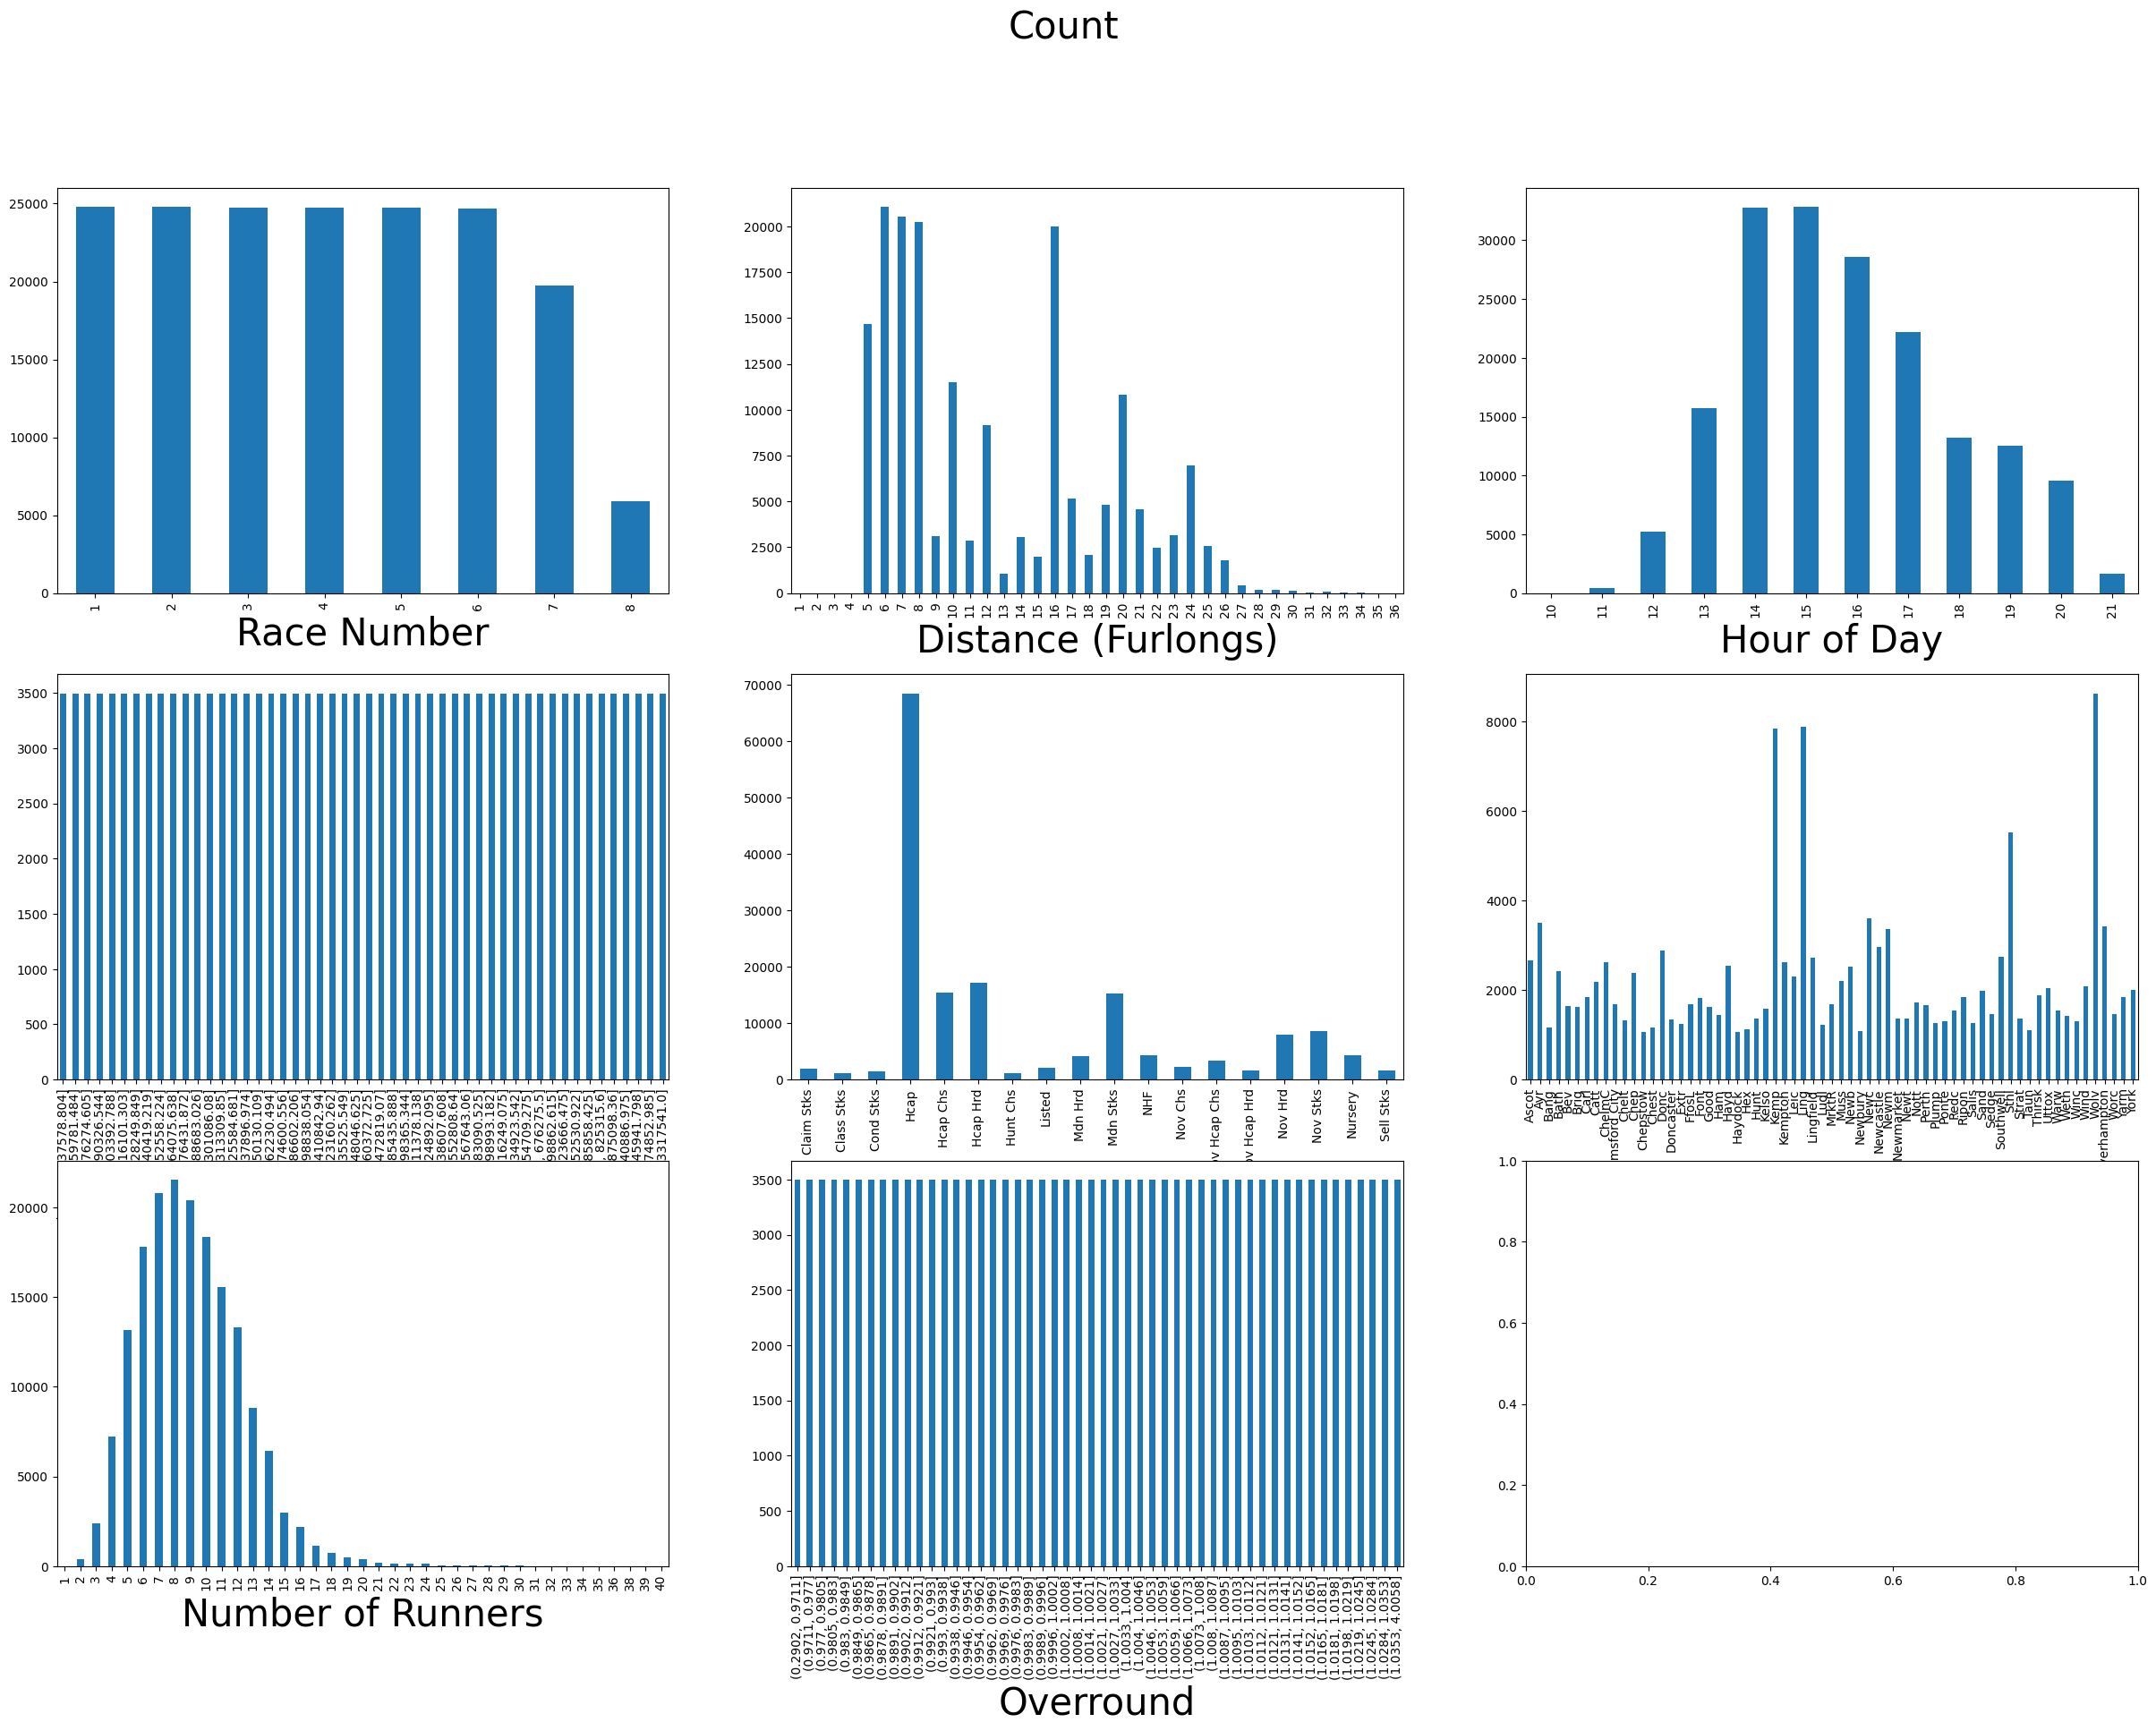

In [53]:
draw(lambda c: c.size(), "Count", kind="bar")

# Analysis

## Test Statistics

### Brier Score

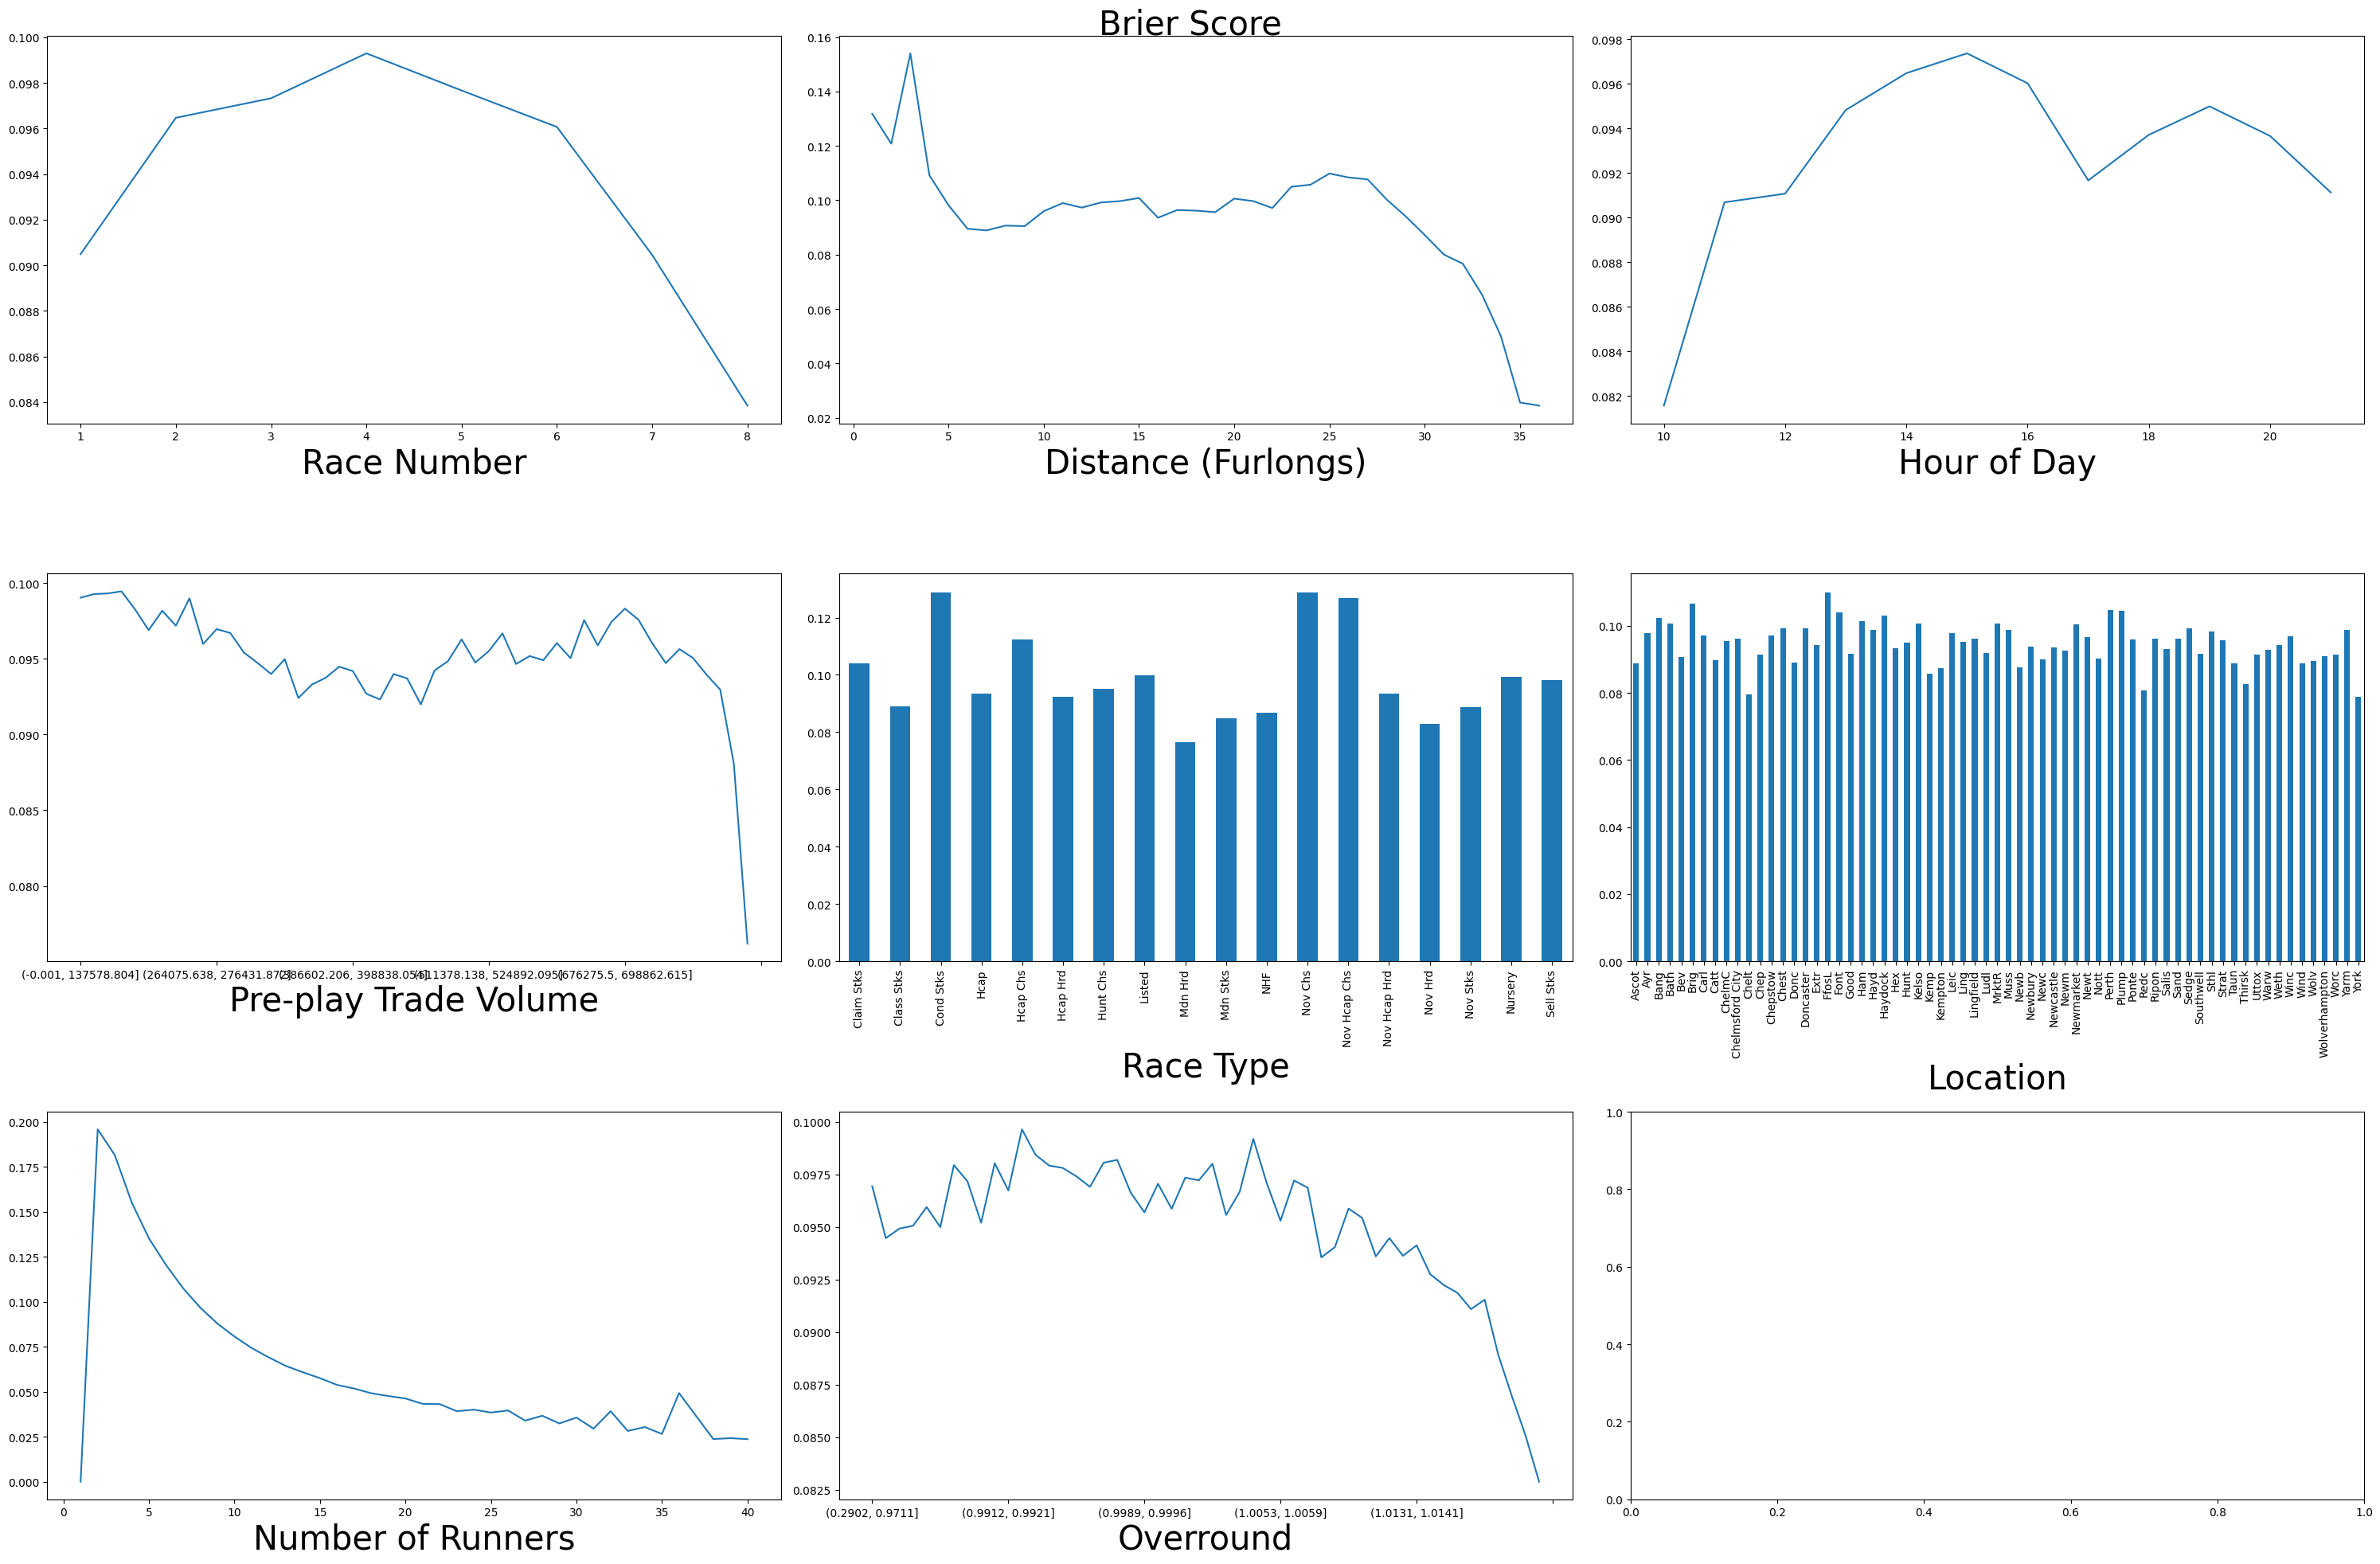

In [38]:
draw(lambda c: c.brier.mean(), "Brier Score")

### Log Loss

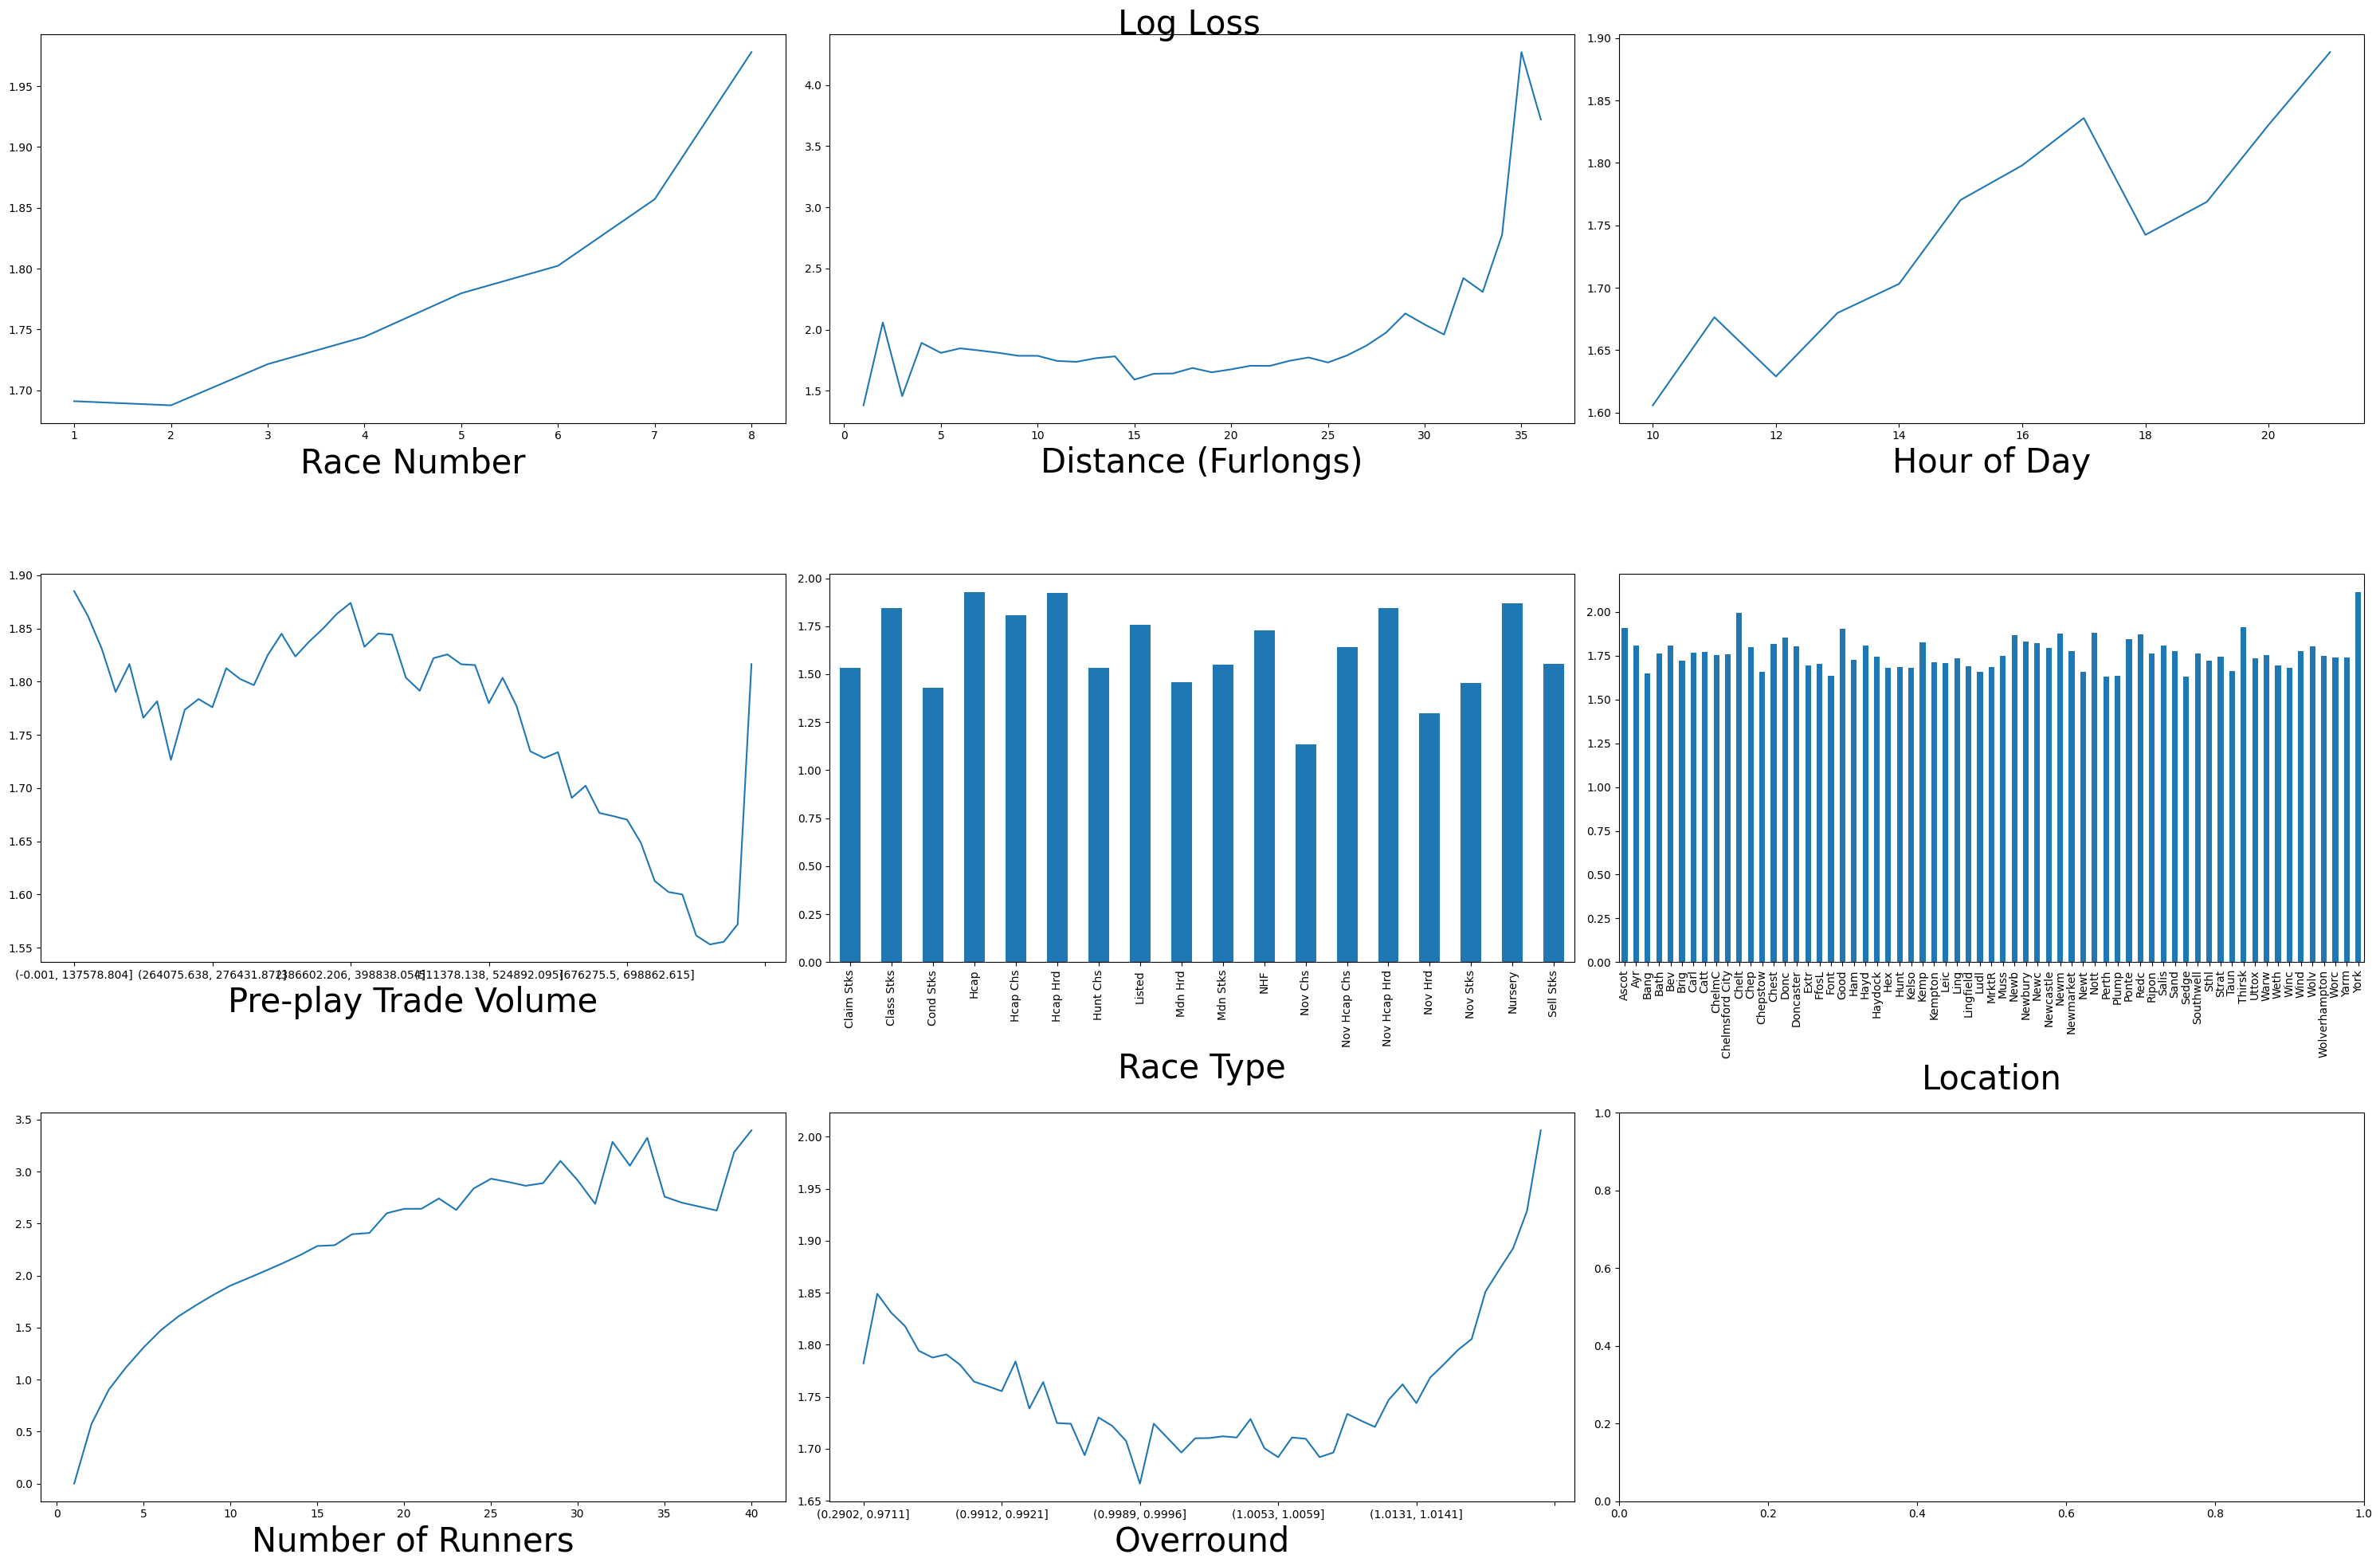

In [39]:
draw(lambda c: c.log_loss.mean(), "Log Loss")

## Trading Strategies

### Prep

In [17]:
favs = runners.sort_values("bsp").groupby("race_id").head(1)

In [18]:
def run_strategy(f, race_groups=None):
    if race_groups is None:
        return f(runners)

    dfs = []
    groups = []
    c_name = race_groups.size().index.name
    for g, df in race_groups:
        groups += [g]
        dfs += [f(runners[runners.race_id.isin(df.index)])]
    return pd.concat(dfs, keys=groups, names=[c_name, "selection_id"]).groupby(level=0)

In [19]:
def create_bets(slip, mode="absolute"):
    bets=slip
    # generate timeline
    bets = bets.join(races[["race_time"]], on="race_id", how="inner").sort_values("race_time")
    # pnl
    

    if mode == "absolute":
        bets["profit"] = (bets.bsp * bets.win_lose -1) * bets.liability
    elif mode == "percentage":
        bets["pct_profit"] = bets.liability*(bets.bsp*bets.win_lose-1)+1
    
    return bets

### Bet on the Favourite

In [20]:
def bet_on_favourite(runners):
    favs = runners.sort_values("bsp").groupby("race_id").head(1)
    slip = favs[["race_id", "selection_id", "win_lose", "bsp"]]
    slip = slip.assign(liability=1)
    slip = slip.assign(back=True)
    return create_bets(slip)

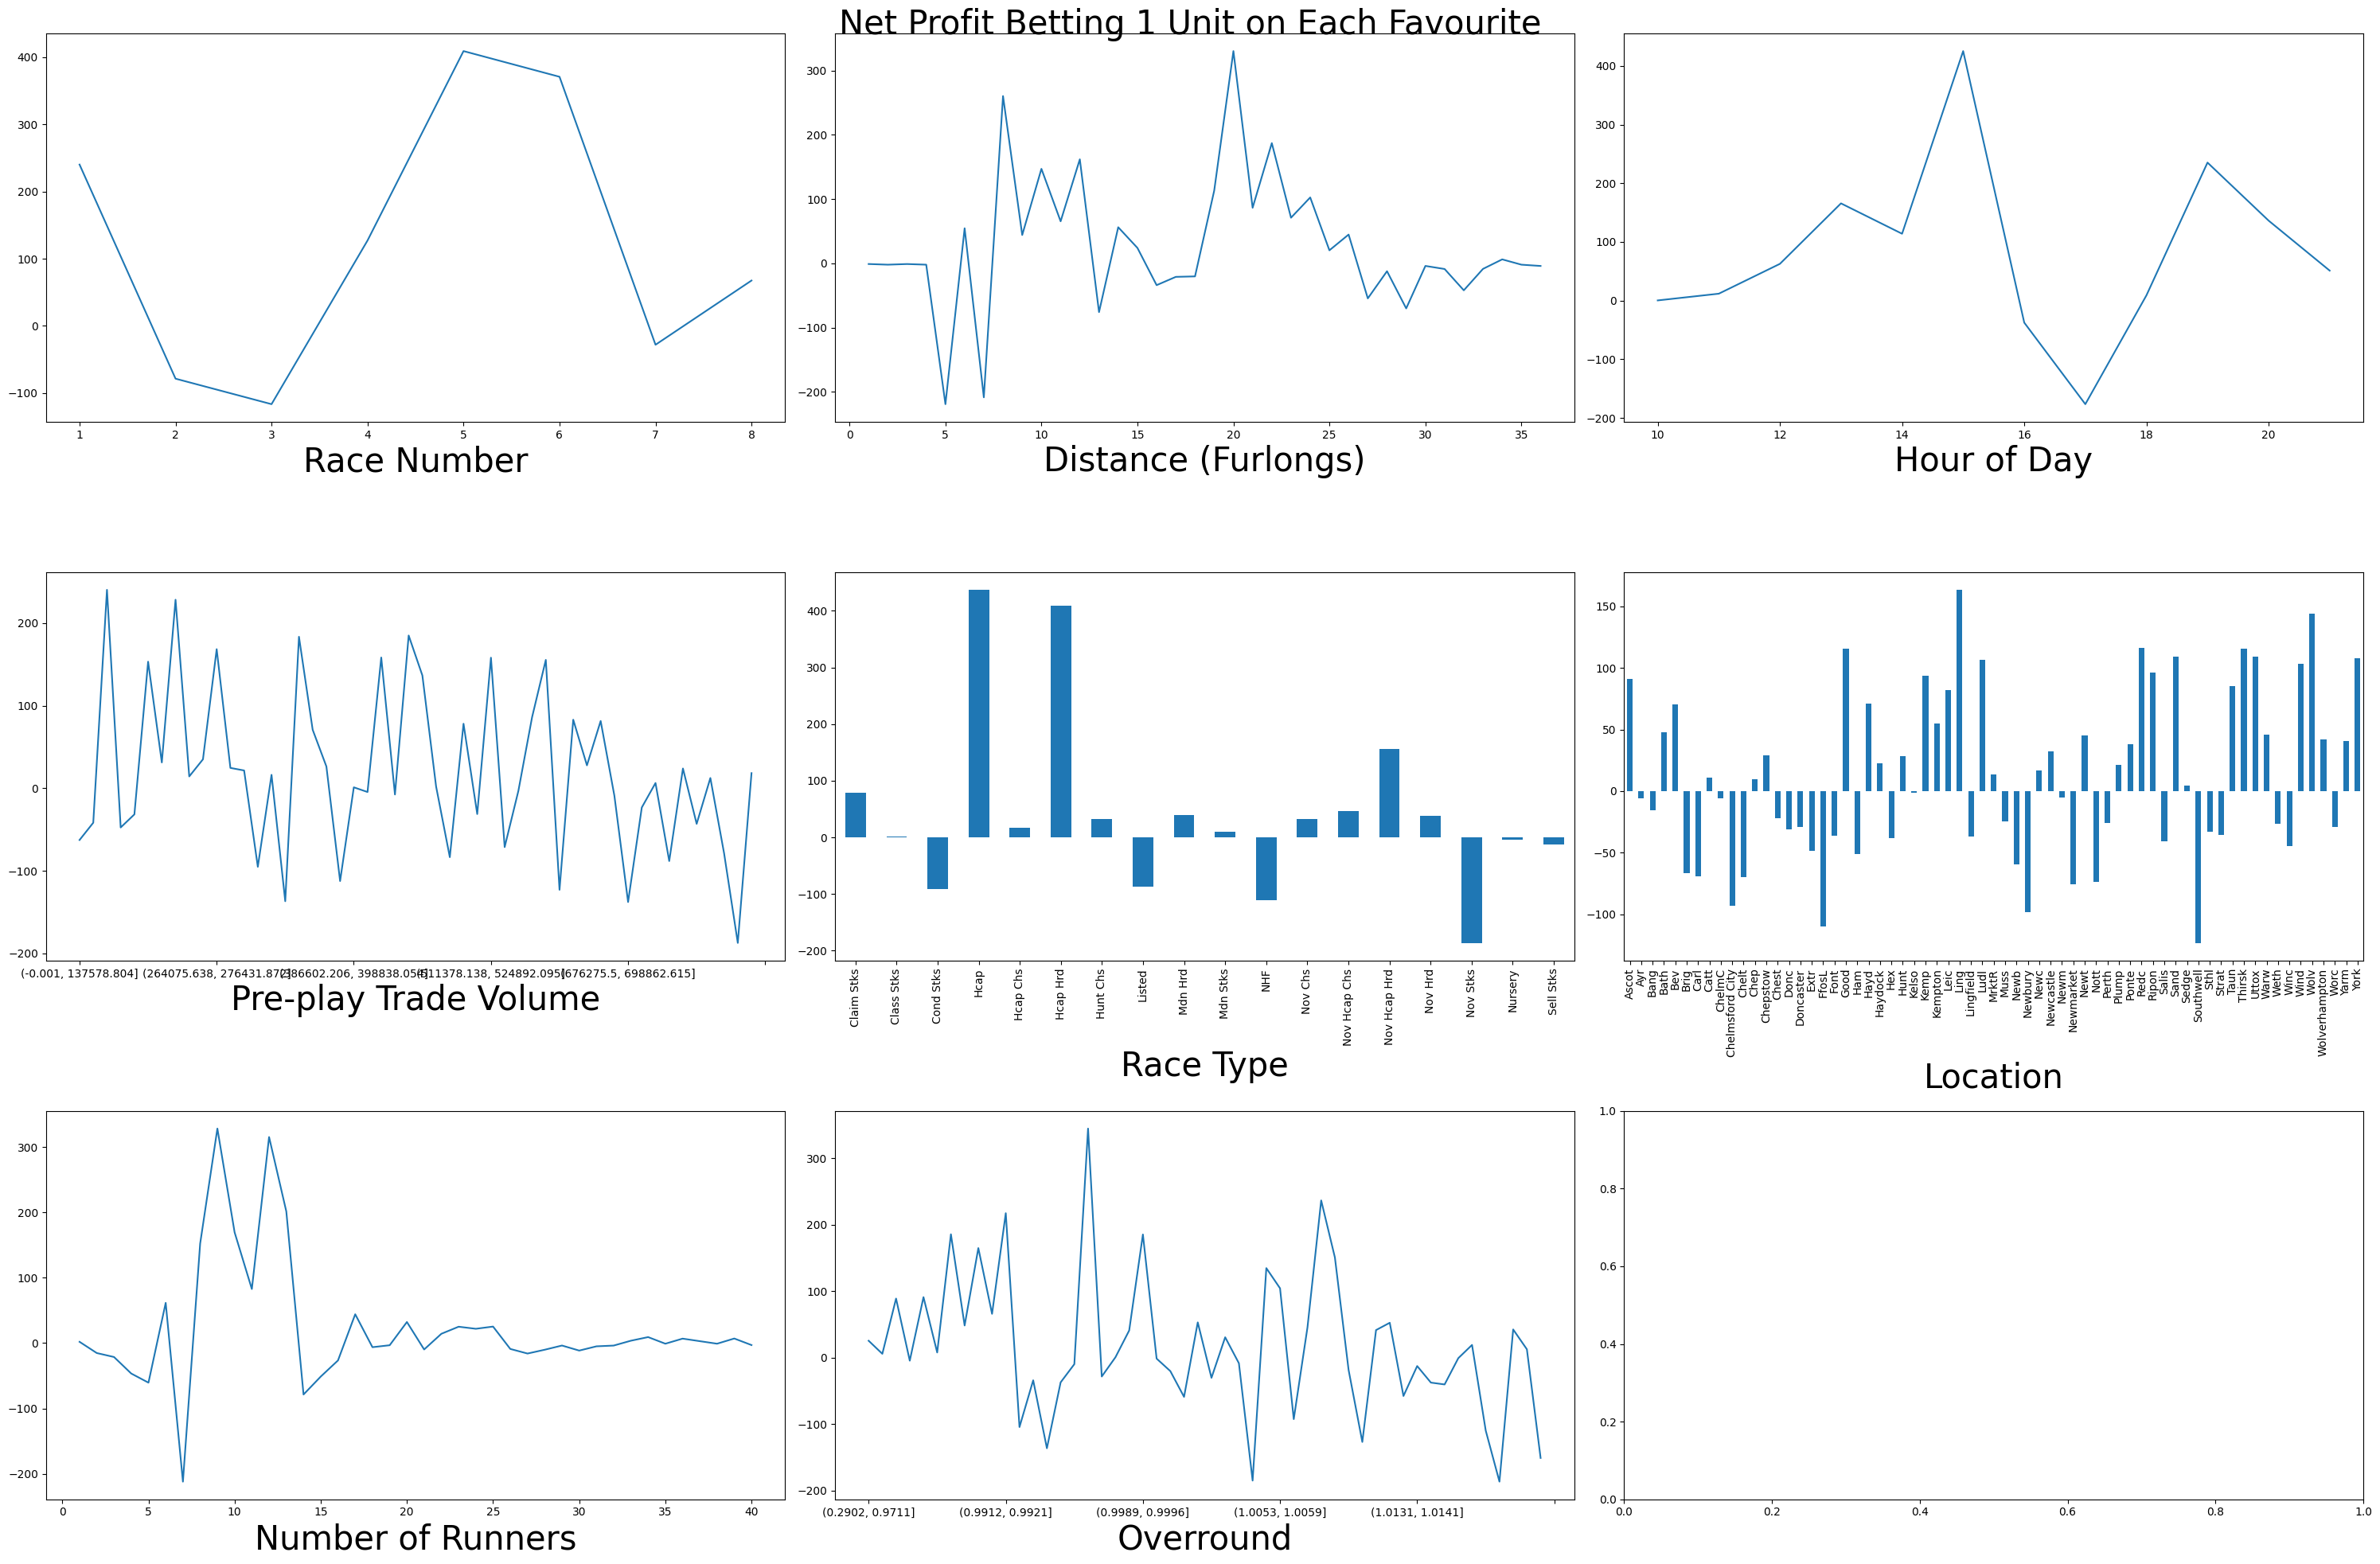

In [40]:
draw(lambda c: run_strategy(bet_on_favourite, c).profit.sum(), "Net Profit Betting 1 Unit on Each Favourite")

### Hedge on the Favourite

In [22]:
def hedge_on_favourite(runners):
    favs = runners.sort_values("bsp").groupby("race_id").head(1)
    slip = favs[["race_id", "selection_id", "win_lose", "bsp"]]
    slip = slip.assign(liability=favs.implied_odds)
    slip = slip.assign(back=True)
    return create_bets(slip)

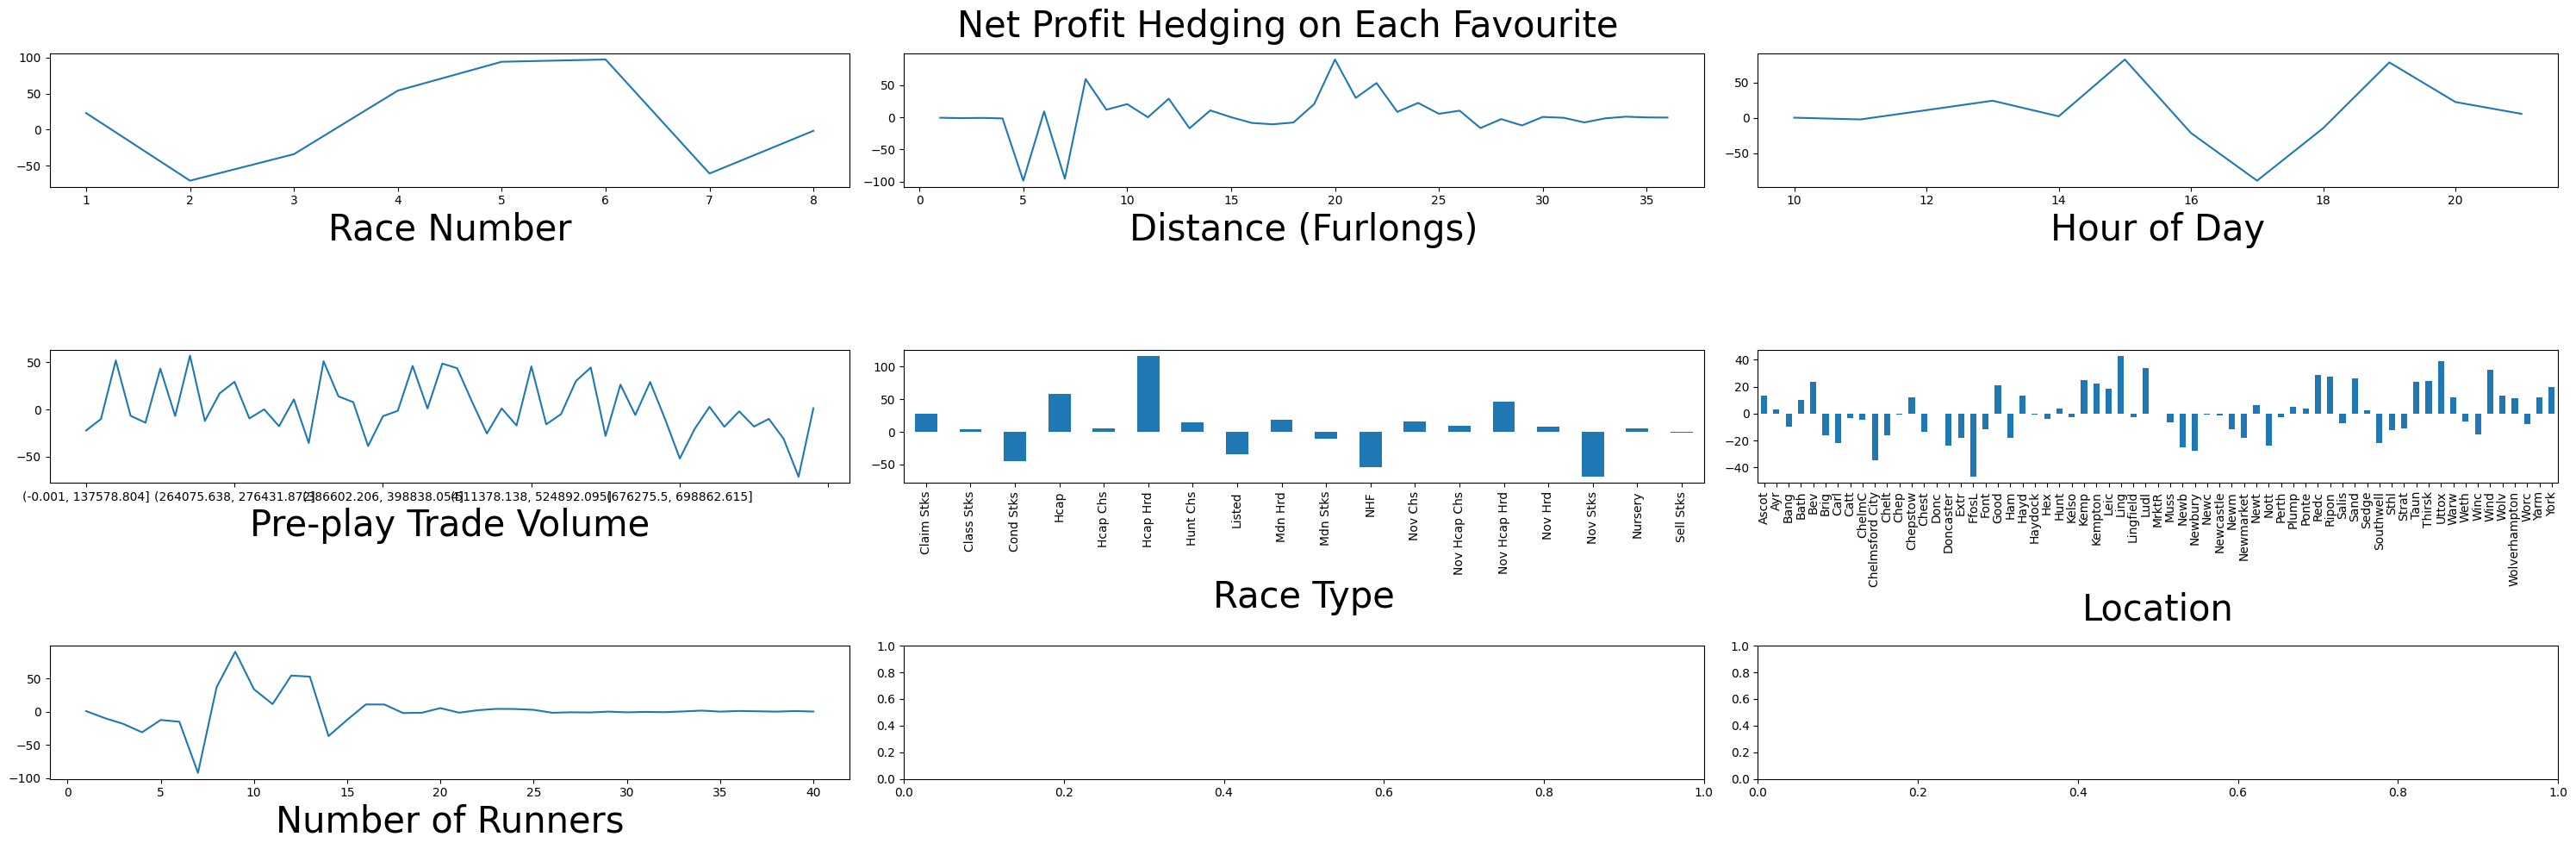

In [23]:
draw(lambda c: run_strategy(hedge_on_favourite, c).profit.sum(), "Net Profit Hedging on Each Favourite")

### Learning Algorithm

In [24]:
def bet_kelly(runners, window_size=500, bet_size=0.08):
    runners = runners.sort_values("bsp").groupby("race_id").head(1)
    p = runners.win_lose.rolling(window_size).mean()
    q = 1-p
    b = runners.bsp-1

    slip = runners[["race_id", "selection_id", "win_lose", "bsp"]]
    slip = slip.assign(liability= p-q/b)
    slip = slip[~slip.liability.isna()]
    slip.liability = slip.liability.clip(lower=0) * bet_size
    
    return create_bets(slip, mode="percentage")

In [25]:
r = {label: run_strategy(bet_kelly, c) for (label, c, _) in categories}

In [26]:
r

{'Race Number': <pandas.api.typing.DataFrameGroupBy object at 0x7435123e0e10>,
 'Distance (Furlongs)': <pandas.api.typing.DataFrameGroupBy object at 0x7435123e1230>,
 'Hour of Day': <pandas.api.typing.DataFrameGroupBy object at 0x7435123e10d0>,
 'Pre-play Trade Volume': <pandas.api.typing.DataFrameGroupBy object at 0x7435123e0f70>,
 'Race Type': <pandas.api.typing.DataFrameGroupBy object at 0x7435123e14f0>,
 'Location': <pandas.api.typing.DataFrameGroupBy object at 0x7435123e0aa0>,
 'Number of Runners': <pandas.api.typing.DataFrameGroupBy object at 0x7435123e1440>}

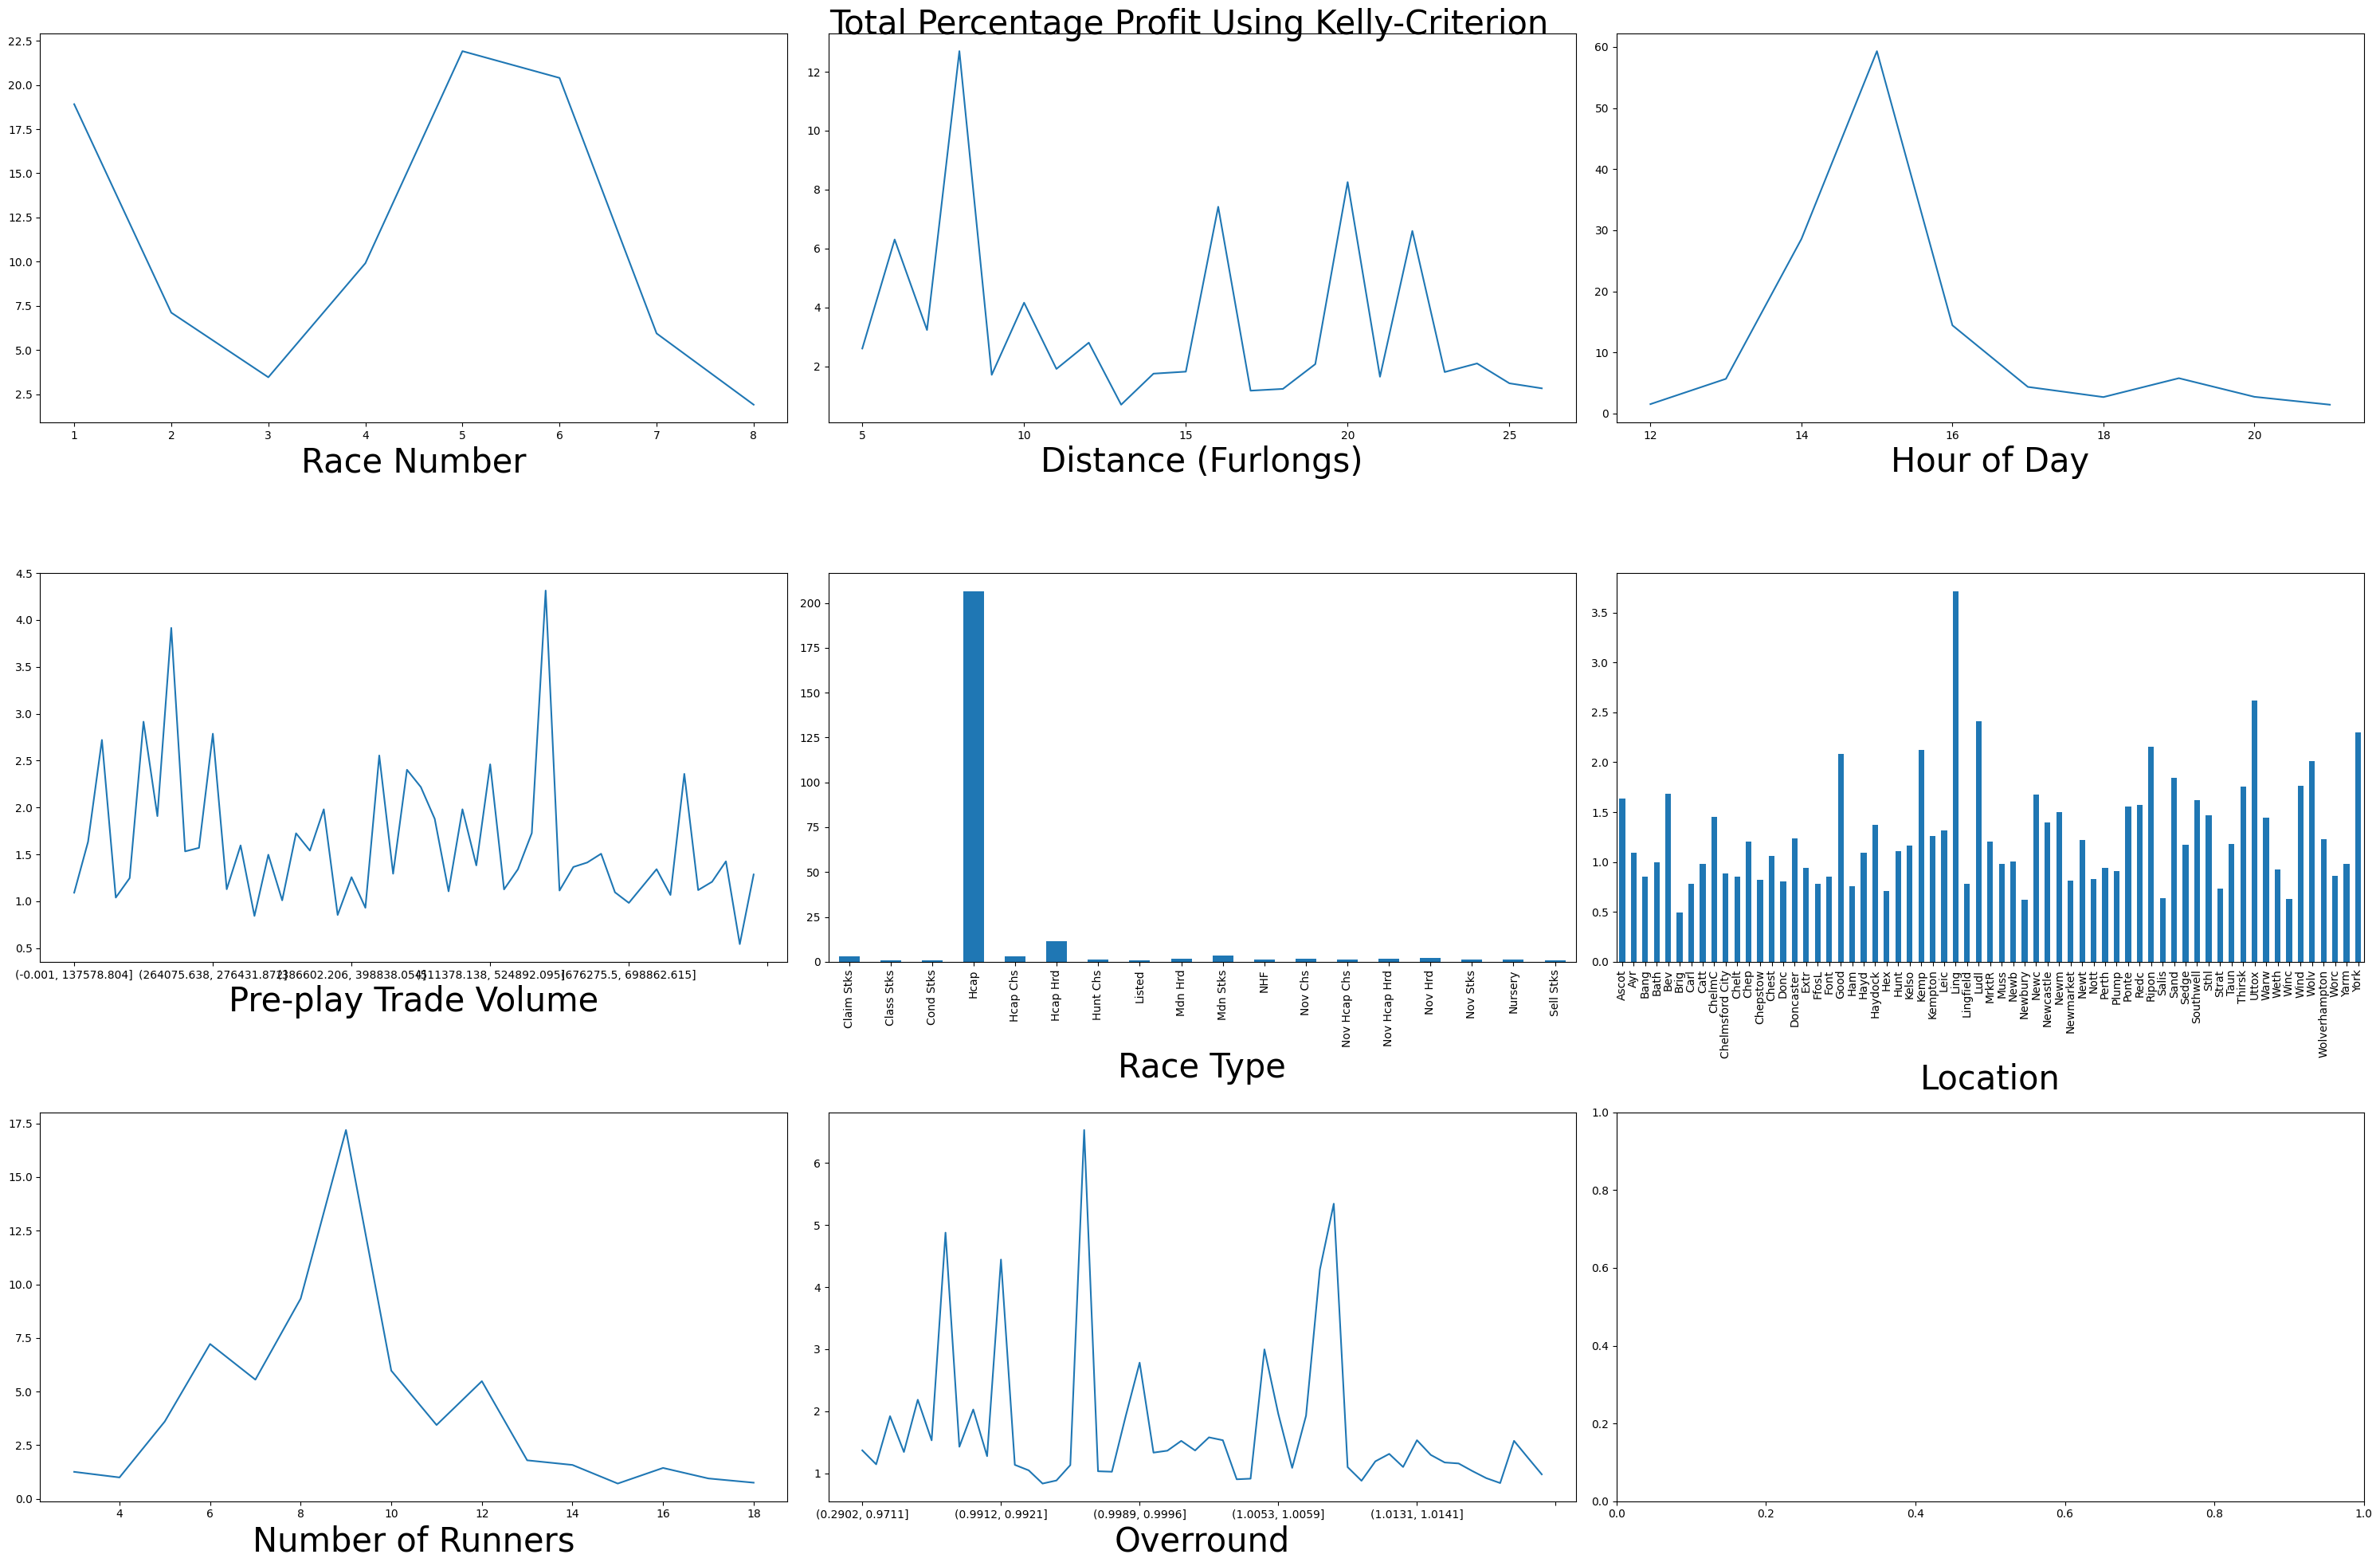

In [41]:
draw(lambda c: run_strategy(bet_kelly, c).pct_profit.prod(), "Total Percentage Profit Using Kelly-Criterion")

In [28]:
r["Race Number"].pct_profit.cumprod()

race_no  selection_id
1        1129962         0.997898
         2786498         1.000549
         3099701         0.999241
         1457311         1.004410
         1559113         1.004410
                           ...   
8        23041465        1.908455
         49957065        1.916089
         95393542        1.908700
         84080011        1.904565
         4007782         1.901165
Name: pct_profit, Length: 170071, dtype: float64

In [29]:
def sharpe_ratio(trades):
    avg_return = trades.pct_profit.mean()-1
    std_dev = trades.pct_profit.std()

    return avg_return/std_dev

In [30]:
sharpe_ratio(r["Race Number"])

race_no
1    0.033046
2    0.024924
3    0.018646
4    0.027869
5    0.036132
6    0.033441
7    0.029232
8    0.029577
Name: pct_profit, dtype: float64

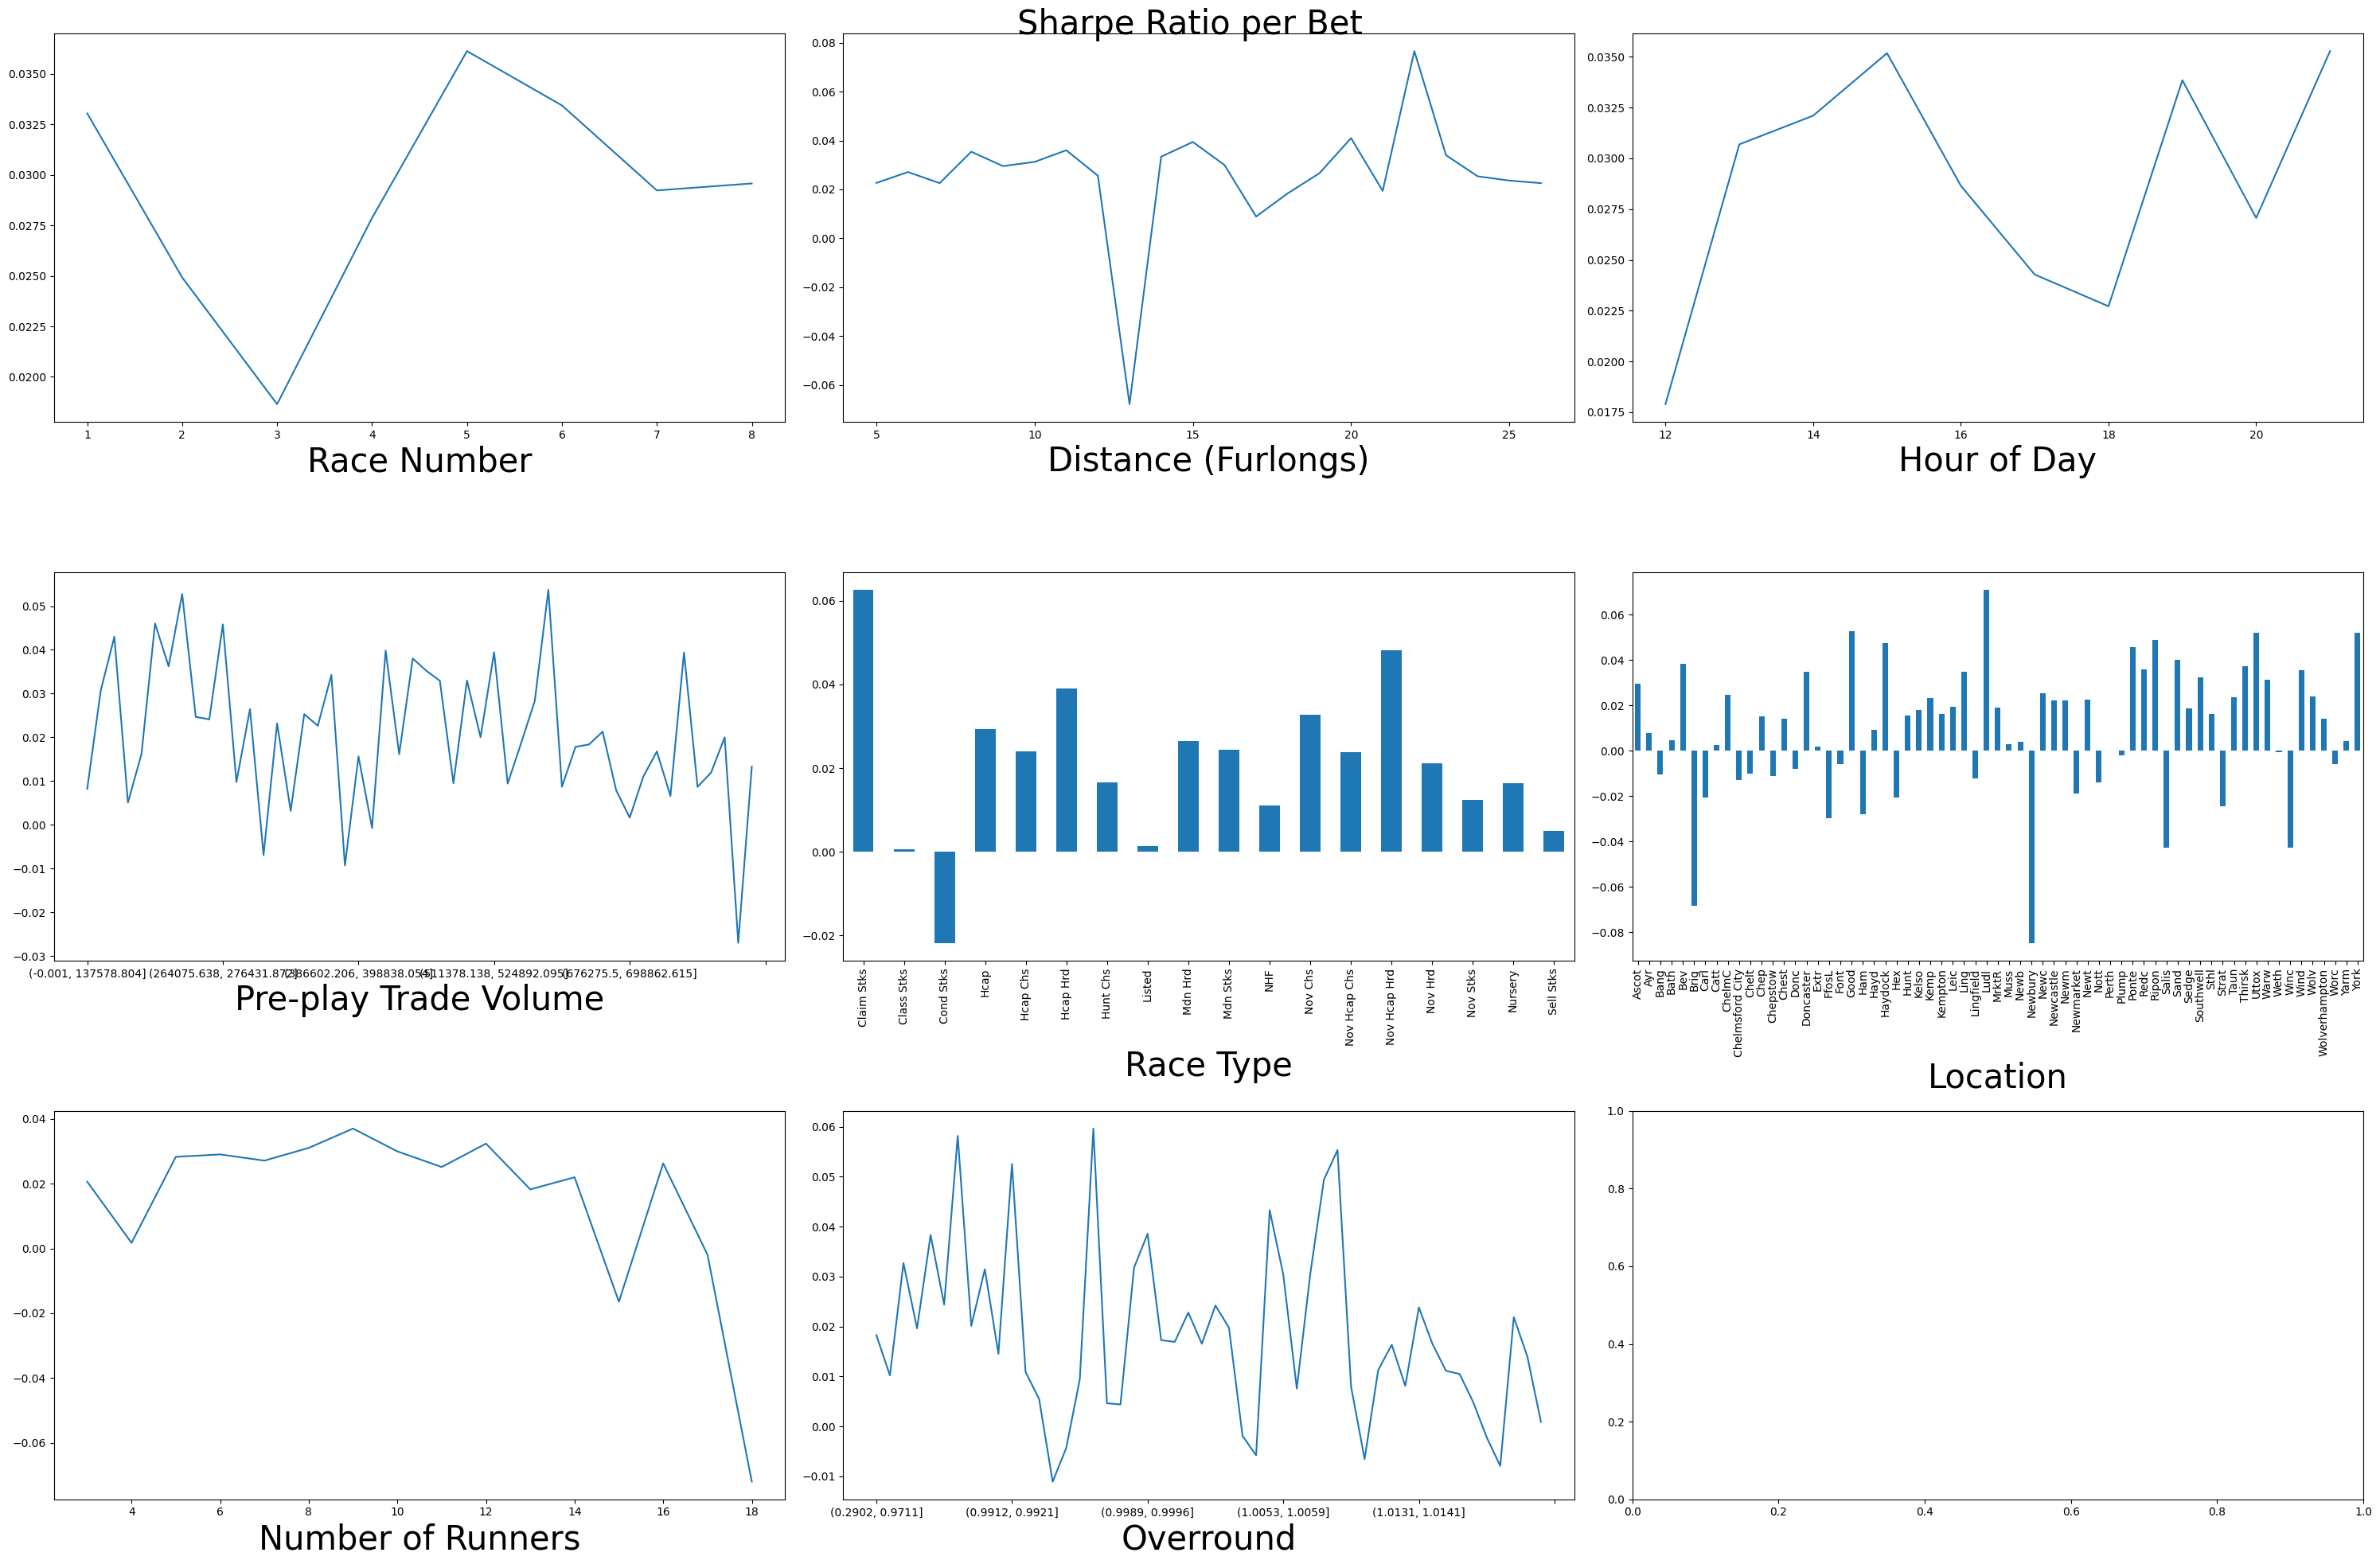

In [42]:
draw(lambda c: sharpe_ratio(run_strategy(bet_kelly, c)), "Sharpe Ratio per Bet")

In [54]:
trades

NameError: name 'trades' is not defined